Cargando dataset limpio (Triclase)...


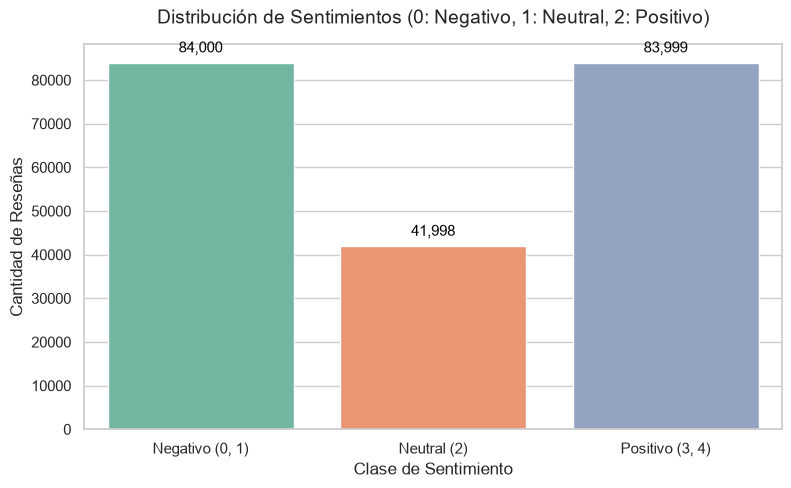

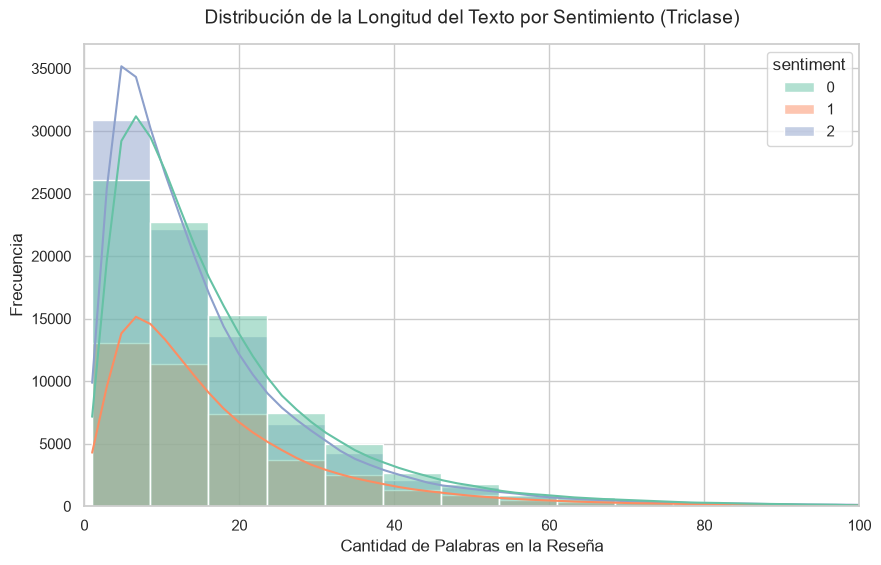

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# 1. Cargar el dataset LIMPIO del enfoque triclase (~210.000 reseñas).
# La ruta relativa '../data/processed/' apunta dentro de la carpeta madre triclase/.
print("Cargando dataset limpio (Triclase)...")
df = pd.read_csv('../data/processed/amazon_reviews_clean.csv')

# Configurar el estilo visual de los gráficos.
sns.set_theme(style="whitegrid")

# ---------------------------------------------------------
# GRÁFICO 1: Balance de clases (Sentimiento en 3 categorías)
# ---------------------------------------------------------
plt.figure(figsize=(9, 5))
ax = sns.countplot(
    data=df,
    x='sentiment',
    order=[0, 1, 2],
    palette='Set2',
    hue='sentiment',
    legend=False
)
plt.title('Distribución de Sentimientos (0: Negativo, 1: Neutral, 2: Positivo)', fontsize=14, pad=15)
plt.xlabel('Clase de Sentimiento', fontsize=12)
plt.ylabel('Cantidad de Reseñas', fontsize=12)

# Etiquetas en el eje X indicando qué calificaciones originales (0 a 4) agrupa cada clase.
plt.xticks(
    ticks=[0, 1, 2],
    labels=['Negativo (0, 1)', 'Neutral (2)', 'Positivo (3, 4)']
)

# Agregar la cantidad exacta de reseñas arriba de cada barra (proporción 40% / 20% / 40%).
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height()):,}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', fontsize=11, color='black',
        xytext=(0, 5), textcoords='offset points'
    )
plt.show()


# ---------------------------------------------------------
# GRÁFICO 2: Distribución de la longitud de las reseñas
# ---------------------------------------------------------
# Calcular cantidad de palabras útiles por cada reseña procesada.
df['word_count'] = df['cleaned_text'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(10, 6))
sns.histplot(
    data=df,
    x='word_count',
    hue='sentiment',
    hue_order=[0, 1, 2],
    bins=50,
    kde=True,
    palette='Set2'
)
plt.title('Distribución de la Longitud del Texto por Sentimiento (Triclase)', fontsize=14, pad=15)
plt.xlabel('Cantidad de Palabras en la Reseña', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)

# Limitamos el eje X a 100 palabras para evitar que valores atípicos extremos deformen el gráfico.
plt.xlim(0, 100)
plt.show()

=== MÉTRICAS DEL CORPUS LIMPIO (TRICLASE) ===
Total de tokens: 3,648,283
Vocabulario único: 54,082
Type-Token Ratio (TTR): 0.0148


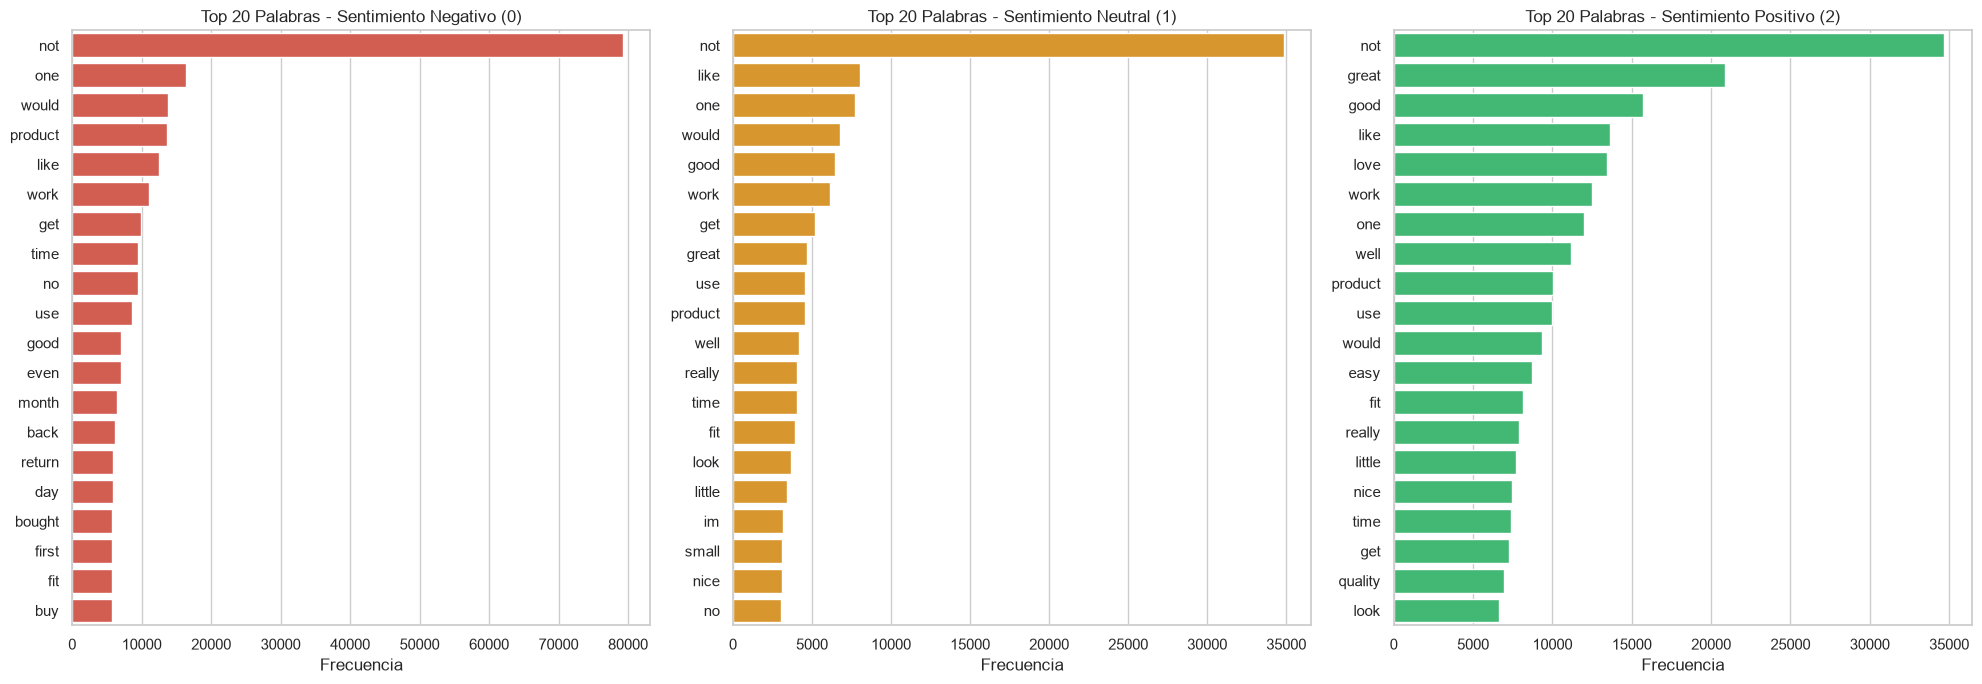

In [2]:
# Agrupación de todos los tokens del corpus triclase procesado.
all_tokens = " ".join(df["cleaned_text"].astype(str)).split()
total_tokens = len(all_tokens)
unique_vocab = len(set(all_tokens))
ttr = unique_vocab / total_tokens

# Presentación de métricas léxicas calculadas.
print("=== MÉTRICAS DEL CORPUS LIMPIO (TRICLASE) ===")
print(f"Total de tokens: {total_tokens:,}")
print(f"Vocabulario único: {unique_vocab:,}")
print(f"Type-Token Ratio (TTR): {ttr:.4f}")

# Separación de tokens según las tres polaridades (0: Negativo, 1: Neutral, 2: Positivo).
neg_tokens = " ".join(df[df["sentiment"] == 0]["cleaned_text"].astype(str)).split()
neu_tokens = " ".join(df[df["sentiment"] == 1]["cleaned_text"].astype(str)).split()
pos_tokens = " ".join(df[df["sentiment"] == 2]["cleaned_text"].astype(str)).split()

# Extracción de las veinte palabras más frecuentes en cada categoría.
top_neg = pd.DataFrame(Counter(neg_tokens).most_common(20), columns=["word", "frequency"])
top_neu = pd.DataFrame(Counter(neu_tokens).most_common(20), columns=["word", "frequency"])
top_pos = pd.DataFrame(Counter(pos_tokens).most_common(20), columns=["word", "frequency"])

# Creación de tres lienzos independientes lado a lado para comparar las tres clases.
fig, (ax_neg, ax_neu, ax_pos) = plt.subplots(1, 3, figsize=(20, 7), sharey=False)

# Gráfico de barras para reseñas negativas (rojo).
sns.barplot(data=top_neg, y="word", x="frequency", ax=ax_neg, color="#e74c3c")
ax_neg.set_title("Top 20 Palabras - Sentimiento Negativo (0)", fontsize=12)
ax_neg.set_xlabel("Frecuencia")
ax_neg.set_ylabel("")

# Gráfico de barras para reseñas neutrales (ámbar).
sns.barplot(data=top_neu, y="word", x="frequency", ax=ax_neu, color="#f39c12")
ax_neu.set_title("Top 20 Palabras - Sentimiento Neutral (1)", fontsize=12)
ax_neu.set_xlabel("Frecuencia")
ax_neu.set_ylabel("")

# Gráfico de barras para reseñas positivas (verde).
sns.barplot(data=top_pos, y="word", x="frequency", ax=ax_pos, color="#2ecc71")
ax_pos.set_title("Top 20 Palabras - Sentimiento Positivo (2)", fontsize=12)
ax_pos.set_xlabel("Frecuencia")
ax_pos.set_ylabel("")

plt.tight_layout()
plt.show()